# TRUSTSR Lab 13 — Authenticated Checkpoints & Ground-Truth Completeness
**Version 1.0 | Evidence class: synthetic security experiment**

## Critical weakness addressed
The prior capstone used boolean placeholders such as `signature_valid=True`, assumed the checkpoint was trusted, and treated a hand-authored ground-truth set as complete. Those are assumptions, not evidence.

This lab replaces them with:
1. **Ed25519 digital signatures** over canonical checkpoint manifests.
2. **Explicit trust-anchor boundary:** signature validity proves that the matching private key signed the bytes; it does not prove that the signer or key is trustworthy.
3. **Scope manifest:** records expected event/artifact IDs, counts, and content hashes.
4. **Fail-closed inventory checks:** omitted, unexpected, duplicated, or modified records invalidate completeness relative to the manifest.
5. **Unknown is not clean:** out-of-scope or insufficiently evidenced artifacts cannot be restored.
6. **Adversarial tests, plots, assertions, and CSV exports.**

**Hard limitation:** No algorithm can prove that its own ground-truth list is complete merely by checking internal consistency. This lab can establish consistency with a declared closed synthetic universe only. Real-world completeness requires independent collection controls and adjudication. These results are not production-security evidence and do not establish worldwide novelty.

## 1. Setup

In [1]:
%pip -q install cryptography pandas matplotlib

In [2]:
from pathlib import Path
from copy import deepcopy
from datetime import datetime, timezone
import hashlib, json, platform
import pandas as pd
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.hazmat.primitives import serialization

RUN_UTC = datetime.now(timezone.utc).isoformat()
EXPERIMENT_ID = "TRUSTSR-L13-SYNTH-001"
OUT_DIR = Path("trustsr_lab13_outputs")
OUT_DIR.mkdir(exist_ok=True)

def canonical_bytes(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")

def sha256_hex(data):
    return hashlib.sha256(data).hexdigest()

print("Experiment:", EXPERIMENT_ID, "| UTC:", RUN_UTC, "| Evidence: synthetic security experiment")

Experiment: TRUSTSR-L13-SYNTH-001 | UTC: 2026-10-11T10:27:45.137253+00:00 | Evidence: synthetic security experiment


## 2. Define the closed synthetic universe and manifest

In [3]:
EVENTS = [
 {"event_id":"E-001","artifact_id":"A-001","kind":"read","source":"trusted_user","label":"benign"},
 {"event_id":"E-002","artifact_id":"A-002","kind":"write","source":"trusted_tool","label":"benign"},
 {"event_id":"E-003","artifact_id":"A-003","kind":"write","source":"untrusted_document","label":"malicious"},
 {"event_id":"E-004","artifact_id":"A-003","kind":"reuse","source":"agent_context","label":"malicious"},
 {"event_id":"E-005","artifact_id":"A-004","kind":"read","source":"unknown_source","label":"unknown"},
]
ARTIFACTS = [
 {"artifact_id":"A-001","expected_state":"clean"},
 {"artifact_id":"A-002","expected_state":"clean"},
 {"artifact_id":"A-003","expected_state":"contaminated"},
 {"artifact_id":"A-004","expected_state":"unknown"},
]

def make_manifest(events, artifacts):
    return {
      "schema_version":"1.0", "experiment_id":EXPERIMENT_ID,
      "event_count":len(events), "artifact_count":len(artifacts),
      "event_ids":sorted(x["event_id"] for x in events),
      "artifact_ids":sorted(x["artifact_id"] for x in artifacts),
      "events_sha256":sha256_hex(canonical_bytes(sorted(events,key=lambda x:x["event_id"]))),
      "artifacts_sha256":sha256_hex(canonical_bytes(sorted(artifacts,key=lambda x:x["artifact_id"]))),
      "scope_rule":"closed synthetic fixture; every listed record is expected to be present"
    }
SCOPE = make_manifest(EVENTS, ARTIFACTS)
display(pd.DataFrame([
 {"inventory":"events","count":SCOPE["event_count"],"ids":", ".join(SCOPE["event_ids"]),"sha256":SCOPE["events_sha256"]},
 {"inventory":"artifacts","count":SCOPE["artifact_count"],"ids":", ".join(SCOPE["artifact_ids"]),"sha256":SCOPE["artifacts_sha256"]}
]))

   inventory  count                                ids                                                            sha256
0     events      5  E-001, E-002, E-003, E-004, E-005  dc5507c4ea0a93dce3730711734e7dda6b44a615892fb5bd3447081818756c4e
1  artifacts      4         A-001, A-002, A-003, A-004  b3ec39e26e6f1a0e3d1cb2b921d2cd84ba1e3d9f1a88b4b644cb046cb1cda7b5

## 3. Completeness audit — relative to the manifest

In [4]:
def audit_inventory(events, artifacts, manifest):
    eids=[e.get("event_id") for e in events]
    aids=[a.get("artifact_id") for a in artifacts]
    checks={
      "event_count_matches":len(events)==manifest["event_count"],
      "event_ids_unique":len(eids)==len(set(eids)),
      "event_id_set_matches":set(eids)==set(manifest["event_ids"]),
      "event_hash_matches":sha256_hex(canonical_bytes(sorted(events,key=lambda x:x["event_id"])))==manifest["events_sha256"],
      "artifact_count_matches":len(artifacts)==manifest["artifact_count"],
      "artifact_ids_unique":len(aids)==len(set(aids)),
      "artifact_id_set_matches":set(aids)==set(manifest["artifact_ids"]),
      "artifact_hash_matches":sha256_hex(canonical_bytes(sorted(artifacts,key=lambda x:x["artifact_id"])))==manifest["artifacts_sha256"],
    }
    return checks, all(checks.values())

scope_checks, scope_ok = audit_inventory(EVENTS, ARTIFACTS, SCOPE)
scope_df = pd.DataFrame([{"check":k,"passed":v,"status":"PASS" if v else "FAIL"} for k,v in scope_checks.items()])
display(scope_df)
assert scope_ok
print("Scope audit PASS means consistent with declared synthetic manifest—not proof of real-world completeness.")

                     check  passed status
0      event_count_matches    True   PASS
1         event_ids_unique    True   PASS
2     event_id_set_matches    True   PASS
3       event_hash_matches    True   PASS
4   artifact_count_matches    True   PASS
5      artifact_ids_unique    True   PASS
6  artifact_id_set_matches    True   PASS
7    artifact_hash_matches    True   PASS

Scope audit PASS means consistent with declared synthetic manifest—not proof of real-world completeness.


## 4. Real Ed25519 signature verification

In [5]:
# Ephemeral key pair for this experiment. Production keys must be protected externally.
private_key = Ed25519PrivateKey.generate()
public_key = private_key.public_key()
public_bytes = public_key.public_bytes(encoding=serialization.Encoding.Raw, format=serialization.PublicFormat.Raw)
PUBLIC_KEY_FINGERPRINT = sha256_hex(public_bytes)
print("Experiment public-key SHA-256 fingerprint:", PUBLIC_KEY_FINGERPRINT)

checkpoint = {
 "schema_version":"1.0", "checkpoint_id":"CKPT-TRUSTED-SYNTH-001",
 "experiment_id":EXPERIMENT_ID, "version":"agent-state-v8",
 "provenance":"controlled-synthetic-clean-state",
 "artifact_ids":["A-001","A-002"],
 "scope_manifest_sha256":sha256_hex(canonical_bytes(SCOPE))
}
signature = private_key.sign(canonical_bytes(checkpoint))

def verify_signature(manifest, sig, pubkey):
    try:
        pubkey.verify(sig, canonical_bytes(manifest))
        return True, "signature_valid"
    except Exception:
        return False, "signature_invalid"

valid, reason = verify_signature(checkpoint, signature, public_key)
wrong_key = Ed25519PrivateKey.generate().public_key()
wrong_key_valid, _ = verify_signature(checkpoint, signature, wrong_key)
tampered = deepcopy(checkpoint); tampered["version"]="agent-state-v999"
tampered_valid, _ = verify_signature(tampered, signature, public_key)
altered_sig = bytes([signature[0] ^ 1]) + signature[1:]
altered_valid, _ = verify_signature(checkpoint, altered_sig, public_key)

sig_df = pd.DataFrame([
 {"scenario":"valid signature", "accepted":valid, "expected":True},
 {"scenario":"wrong public key", "accepted":wrong_key_valid, "expected":False},
 {"scenario":"tampered manifest", "accepted":tampered_valid, "expected":False},
 {"scenario":"tampered signature bytes", "accepted":altered_valid, "expected":False},
])
sig_df["test_passed"] = sig_df["accepted"] == sig_df["expected"]
sig_df["evidence_classification"]="synthetic cryptographic test"
display(sig_df)
assert sig_df["test_passed"].all()
assert int(sig_df["accepted"].sum()) == 1

Experiment public-key SHA-256 fingerprint: 971dfaa8effd12cde7f0b026b1b7fba770657ce349cb8fddaf08c84ed6e77864


                   scenario  accepted  expected  test_passed       evidence_classification
0           valid signature      True      True         True  synthetic cryptographic test
1          wrong public key     False     False         True  synthetic cryptographic test
2         tampered manifest     False     False         True  synthetic cryptographic test
3  tampered signature bytes     False     False         True  synthetic cryptographic test

## 5. Bind checkpoint to scope; test inventory failures

In [6]:
def verify_bundle(cp, sig, pubkey, events, artifacts, scope):
    sig_ok, _ = verify_signature(cp, sig, pubkey)
    _, inventory_ok = audit_inventory(events, artifacts, scope)
    scope_hash_ok = cp.get("scope_manifest_sha256") == sha256_hex(canonical_bytes(scope))
    artifacts_in_scope = set(cp.get("artifact_ids", [])) <= set(scope["artifact_ids"])
    checks={"signature_valid":sig_ok, "inventory_complete_relative_to_manifest":inventory_ok,
            "checkpoint_bound_to_scope":scope_hash_ok, "checkpoint_artifacts_in_scope":artifacts_in_scope}
    return checks, all(checks.values())

bundle_checks, bundle_ok = verify_bundle(checkpoint, signature, public_key, EVENTS, ARTIFACTS, SCOPE)
display(pd.DataFrame([{"check":k,"passed":v} for k,v in bundle_checks.items()]))
assert bundle_ok

inventory_cases=[]
def test_inventory(name, events, artifacts, expected):
    checks, ok = audit_inventory(events, artifacts, SCOPE)
    inventory_cases.append({"scenario":name,"accepted_complete":ok,"expected":expected,
      "test_passed":ok==expected,"failed_checks":"|".join(k for k,v in checks.items() if not v),
      "evidence_classification":"synthetic inventory integrity test"})

test_inventory("unchanged",deepcopy(EVENTS),deepcopy(ARTIFACTS),True)
test_inventory("event omitted",deepcopy(EVENTS[:-1]),deepcopy(ARTIFACTS),False)
test_inventory("unexpected event",deepcopy(EVENTS)+[{"event_id":"E-999","artifact_id":"A-999","kind":"write","source":"unknown","label":"unknown"}],deepcopy(ARTIFACTS),False)
test_inventory("duplicate event ID",deepcopy(EVENTS)+[deepcopy(EVENTS[0])],deepcopy(ARTIFACTS),False)
test_inventory("artifact omitted",deepcopy(EVENTS),deepcopy(ARTIFACTS[:-1]),False)
modified=deepcopy(EVENTS); modified[0]["source"]="tampered"
test_inventory("event content modified",modified,deepcopy(ARTIFACTS),False)
inventory_df=pd.DataFrame(inventory_cases)
display(inventory_df)
assert inventory_df["test_passed"].all()
assert inventory_df.loc[inventory_df.scenario!="unchanged","accepted_complete"].eq(False).all()

# Even a freshly signed checkpoint cannot name an artifact outside the manifest scope.
oos=deepcopy(checkpoint); oos["artifact_ids"].append("A-999")
oos_sig=private_key.sign(canonical_bytes(oos))
oos_checks,oos_ok=verify_bundle(oos,oos_sig,public_key,EVENTS,ARTIFACTS,SCOPE)
assert not oos_ok and not oos_checks["checkpoint_artifacts_in_scope"]
print("Out-of-scope checkpoint rejected.")

                                     check  passed
0                          signature_valid    True
1  inventory_complete_relative_to_manifest    True
2                checkpoint_bound_to_scope    True
3            checkpoint_artifacts_in_scope    True

                 scenario  accepted_complete  expected  test_passed                                                         failed_checks             evidence_classification
0               unchanged               True      True         True                                                                        synthetic inventory integrity test
1           event omitted              False     False         True           event_count_matches|event_id_set_matches|event_hash_matches  synthetic inventory integrity test
2        unexpected event              False     False         True           event_count_matches|event_id_set_matches|event_hash_matches  synthetic inventory integrity test
3      duplicate event ID              False     False         True               event_count_matches|event_ids_unique|event_hash_matches  synthetic inventory integrity test
4        artifact omitted              False     False         True  artifact_count_matches|artifact_id_set_matches|artifact_hash_

Out-of-scope checkpoint rejected.


## 6. Unknown is not clean; guarded recovery decision

In [7]:
def classify(artifact_id, events, cp, bundle_valid, scope):
    if not bundle_valid or artifact_id not in set(scope["artifact_ids"]):
        return "Unknown", "bundle_invalid_or_out_of_scope"
    writes=[e for e in events if e["artifact_id"]==artifact_id and e["kind"]=="write"]
    if any(e["label"]=="malicious" and e["source"]=="untrusted_document" for e in writes):
        return "Contaminated", "untrusted malicious write in fixture"
    if artifact_id in set(cp["artifact_ids"]):
        return "Trusted", "included in authenticated checkpoint"
    if any(e["source"]=="unknown_source" for e in events if e["artifact_id"]==artifact_id):
        return "Unknown", "source provenance unavailable"
    return "Unknown", "no positive clean provenance"

classification=[]
for a in ARTIFACTS:
    state,why=classify(a["artifact_id"],EVENTS,checkpoint,bundle_ok,SCOPE)
    classification.append({"artifact_id":a["artifact_id"],"state":state,"reason":why})
classification_df=pd.DataFrame(classification)
display(classification_df)
state_map=classification_df.set_index("artifact_id")["state"].to_dict()
assert state_map["A-001"]=="Trusted"
assert state_map["A-003"]=="Contaminated"
assert state_map["A-004"]=="Unknown"
assert classify("A-999",EVENTS,checkpoint,bundle_ok,SCOPE)[0]=="Unknown"

def recovery_gate(checks, restore_states):
    if not all(checks.values()): return "FAIL","integrity_or_scope_check_failed"
    if "Contaminated" in restore_states: return "FAIL","contaminated_artifact_in_restore_set"
    if "Unknown" in restore_states: return "FAIL","unknown_artifact_in_restore_set"
    return "PASS","all_declared_gates_passed"

decisions=[]
for name, checks, states in [
 ("nominal clean restore",bundle_checks,[state_map["A-001"],state_map["A-002"]]),
 ("tampered/out-of-scope checkpoint",oos_checks,[state_map["A-001"]]),
 ("contaminated restore attempt",bundle_checks,[state_map["A-001"],"Contaminated"]),
 ("unknown restore attempt",bundle_checks,[state_map["A-001"],"Unknown"]),
]:
    verdict,why=recovery_gate(checks,states)
    decisions.append({"scenario":name,"verdict":verdict,"reason":why,"evidence_classification":"synthetic policy test"})
decision_df=pd.DataFrame(decisions)
display(decision_df)
assert decision_df.iloc[0]["verdict"]=="PASS"
assert decision_df.iloc[1:]["verdict"].eq("FAIL").all()

  artifact_id         state                                reason
0       A-001       Trusted  included in authenticated checkpoint
1       A-002       Trusted  included in authenticated checkpoint
2       A-003  Contaminated  untrusted malicious write in fixture
3       A-004       Unknown         source provenance unavailable

                           scenario verdict                                reason evidence_classification
0             nominal clean restore    PASS             all_declared_gates_passed   synthetic policy test
1  tampered/out-of-scope checkpoint    FAIL       integrity_or_scope_check_failed   synthetic policy test
2      contaminated restore attempt    FAIL  contaminated_artifact_in_restore_set   synthetic policy test
3           unknown restore attempt    FAIL       unknown_artifact_in_restore_set   synthetic policy test

## 7. Plots

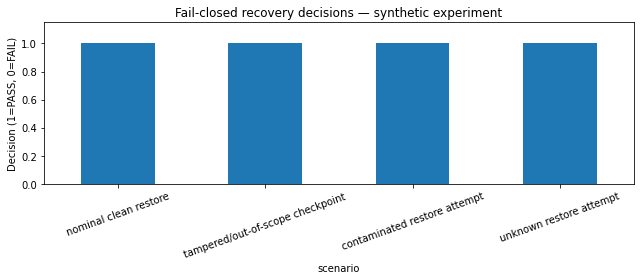

In [8]:
ax=sig_df.set_index("scenario")["test_passed"].astype(int).plot(kind="bar",figsize=(9,4),title="Ed25519 authentication tests — synthetic experiment")
ax.set_ylabel("Test passed (1=yes, 0=no)"); ax.set_ylim(0,1.15); ax.tick_params(axis="x",rotation=20); plt.tight_layout(); plt.show()

ax=inventory_df.set_index("scenario")["test_passed"].astype(int).plot(kind="bar",figsize=(10,4),title="Ground-truth inventory integrity tests — synthetic experiment")
ax.set_ylabel("Expected behavior passed (1=yes, 0=no)"); ax.set_ylim(0,1.15); ax.tick_params(axis="x",rotation=20); plt.tight_layout(); plt.show()

ax=decision_df.set_index("scenario")["verdict"].map({"PASS":1,"FAIL":0}).plot(kind="bar",figsize=(9,4),title="Fail-closed recovery decisions — synthetic experiment")
ax.set_ylabel("Decision (1=PASS, 0=FAIL)"); ax.set_ylim(0,1.15); ax.tick_params(axis="x",rotation=20); plt.tight_layout(); plt.show()

## 8. Export CSVs and run manifest

In [9]:
(OUT_DIR/"trustsr_l13_scope_manifest.json").write_text(json.dumps(SCOPE,indent=2,sort_keys=True),encoding="utf-8")
run_manifest={
 "experiment_id":EXPERIMENT_ID,"run_utc":RUN_UTC,"evidence_classification":"synthetic security experiment",
 "python_version":platform.python_version(),"public_key_fingerprint_sha256":PUBLIC_KEY_FINGERPRINT,
 "scope_manifest_sha256":sha256_hex(canonical_bytes(SCOPE)),
 "signature_tests_all_passed":bool(sig_df.test_passed.all()),
 "inventory_tests_all_passed":bool(inventory_df.test_passed.all()),
 "nominal_recovery_verdict":decision_df.iloc[0]["verdict"],
 "adversarial_recovery_verdicts":decision_df.iloc[1:]["verdict"].tolist()
}
(OUT_DIR/"trustsr_l13_run_manifest.json").write_text(json.dumps(run_manifest,indent=2,sort_keys=True),encoding="utf-8")
exports={
 "trustsr_l13_scope_audit.csv":scope_df,
 "trustsr_l13_signature_tests.csv":sig_df,
 "trustsr_l13_inventory_tests.csv":inventory_df,
 "trustsr_l13_artifact_classification.csv":classification_df,
 "trustsr_l13_recovery_decisions.csv":decision_df,
}
for name,df in exports.items():
    path=OUT_DIR/name; df.to_csv(path,index=False)
    assert path.exists() and path.stat().st_size>0
    print("Exported",path,"rows=",len(df),"bytes=",path.stat().st_size)
assert sig_df.test_passed.all() and inventory_df.test_passed.all()
assert decision_df.iloc[0]["verdict"]=="PASS" and decision_df.iloc[1:]["verdict"].eq("FAIL").all()
print("ALL ASSERTIONS PASSED — synthetic experiment only.")

Exported trustsr_lab13_outputs/trustsr_l13_scope_audit.csv rows= 8 bytes= 266
Exported trustsr_lab13_outputs/trustsr_l13_signature_tests.csv rows= 4 bytes= 321
Exported trustsr_lab13_outputs/trustsr_l13_inventory_tests.csv rows= 6 bytes= 761
Exported trustsr_lab13_outputs/trustsr_l13_artifact_classification.csv rows= 4 bytes= 227
Exported trustsr_lab13_outputs/trustsr_l13_recovery_decisions.csv rows= 4 bytes= 391
ALL ASSERTIONS PASSED — synthetic experiment only.


## 9. Interpretation and publication wording

### Supported by this run
- The real Ed25519 library verification accepted the valid signature and rejected a wrong key, modified manifest, and modified signature.
- Inventory auditing detected missing, unexpected, duplicated, and altered records **relative to the declared manifest**.
- The checkpoint was bound to a scope-manifest hash; an out-of-scope artifact was rejected even when the altered manifest was newly signed by the experiment key.
- Unknown and contaminated artifacts were blocked from the restore set.

### Not established
- The ephemeral key is not a production trust anchor; no independent authority provisions the public key here.
- A signature does not prove the checkpoint is semantically clean or the signer is trustworthy.
- A scope manifest cannot prove absolute completeness of data collection. It only lets us detect mismatch against a declared inventory.
- No real agent, external telemetry pipeline, production key-management system, or competing baseline was tested.

### Suggested paper wording
“We replaced boolean checkpoint-trust flags with Ed25519 signature verification and introduced a scope manifest binding the experiment to explicit event and artifact inventories. Synthetic adversarial tests detected signature tampering, wrong-key verification, omitted or unexpected records, duplicate identifiers, modified event content, and out-of-scope restore artifacts. These results establish implementation behavior against the declared synthetic fixtures only; trust-anchor security and real-world ground-truth completeness remain unvalidated.”

### Production-grade next steps
1. Provision public keys independently; never trust a key bundled with the checkpoint.
2. Keep signing keys in a KMS/HSM or isolated signing service; implement rotation, revocation, access control, and audit.
3. Sign collection manifests at ingestion; track dropped-event counters, sequence gaps, sensor health, and missing telemetry.
4. Establish ground truth independently from detector inputs and document adjudication.
5. Add replay/stale-checkpoint tests, key-compromise tests, partial collection failures, and real agent-runtime integration.
6. Compare against documented baselines and publish code, environment, raw traces, and failure cases.

**Evidence boundary:** All experiment outcomes are synthetic. The signature operations use a real cryptographic library, but this notebook is not a production security architecture or proof of universal completeness.